In [2]:
import pandas as pd

df = pd.read_csv("../Data/train.csv")

print(df.head())
print(df.shape)
print(df.columns)

   Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0       1  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
1       2  CA-2017-152156  08/11/2017  11/11/2017    Second Class    CG-12520   
2       3  CA-2017-138688  12/06/2017  16/06/2017    Second Class    DV-13045   
3       4  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   
4       5  US-2016-108966  11/10/2016  18/10/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City       State  \
0      Claire Gute   Consumer  United States        Henderson    Kentucky   
1      Claire Gute   Consumer  United States        Henderson    Kentucky   
2  Darrin Van Huff  Corporate  United States      Los Angeles  California   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale     Florida   

   Postal Code Region       Product ID         Cat

In [ ]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object


In [ ]:
print(df.isnull().sum())


Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
dtype: int64


In [ ]:
print(df.describe())

            Row ID   Postal Code         Sales
count  9800.000000   9789.000000   9800.000000
mean   4900.500000  55273.322403    230.769059
std    2829.160653  32041.223413    626.651875
min       1.000000   1040.000000      0.444000
25%    2450.750000  23223.000000     17.248000
50%    4900.500000  58103.000000     54.490000
75%    7350.250000  90008.000000    210.605000
max    9800.000000  99301.000000  22638.480000


In [ ]:
print(df.nunique())

Row ID           9800
Order ID         4922
Order Date       1230
Ship Date        1326
Ship Mode           4
Customer ID       793
Customer Name     793
Segment             3
Country             1
City              529
State              49
Postal Code       626
Region              4
Product ID       1861
Category            3
Sub-Category       17
Product Name     1849
Sales            5757
Year                4
Month              12
Month_Name         12
dtype: int64


In [ ]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   str    
 2   Order Date     9800 non-null   str    
 3   Ship Date      9800 non-null   str    
 4   Ship Mode      9800 non-null   str    
 5   Customer ID    9800 non-null   str    
 6   Customer Name  9800 non-null   str    
 7   Segment        9800 non-null   str    
 8   Country        9800 non-null   str    
 9   City           9800 non-null   str    
 10  State          9800 non-null   str    
 11  Postal Code    9789 non-null   float64
 12  Region         9800 non-null   str    
 13  Product ID     9800 non-null   str    
 14  Category       9800 non-null   str    
 15  Sub-Category   9800 non-null   str    
 16  Product Name   9800 non-null   str    
 17  Sales          9800 non-null   float64
dtypes: float64(2), int6

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df[df.duplicated()]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales


In [ ]:
df = df.drop_duplicates()

In [ ]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    dayfirst=True
)

In [ ]:
print(df["Order Date"].head())
print(df["Order Date"].dtype)

0   2017-11-08
1   2017-11-08
2   2017-06-12
3   2016-10-11
4   2016-10-11
Name: Order Date, dtype: datetime64[us]
datetime64[us]


In [ ]:
print(df["Order Date"] == pd.to_datetime(df["Order Date"]))

0       True
1       True
2       True
3       True
4       True
        ... 
9795    True
9796    True
9797    True
9798    True
9799    True
Name: Order Date, Length: 9800, dtype: bool


In [ ]:
print(df["Year"] == df["Order Date"].dt.year)
print(df["Month"] == df["Order Date"].dt.month)
print(df["Month_Name"] == df["Order Date"].dt.month_name())

0       True
1       True
2       True
3       True
4       True
        ... 
9795    True
9796    True
9797    True
9798    True
9799    True
Length: 9800, dtype: bool
0       True
1       True
2       True
3       True
4       True
        ... 
9795    True
9796    True
9797    True
9798    True
9799    True
Length: 9800, dtype: bool
0       True
1       True
2       True
3       True
4       True
        ... 
9795    True
9796    True
9797    True
9798    True
9799    True
Length: 9800, dtype: bool


In [ ]:
total_sales = df["Sales"].sum()
print(total_sales)

2261536.7827


In [ ]:
total_orders = df["Order ID"].nunique()
print(total_orders)

4922


In [ ]:
total_customers = df["Customer ID"].nunique()
print(total_customers)

793


In [ ]:
average_order_value = total_sales / total_orders
print(average_order_value)

459.4751691791954


In [ ]:
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

Total rows: 9800
Total columns: 21


In [ ]:
missing = df.isnull().sum()
print(missing[missing > 0])

Postal Code    11
dtype: int64


In [ ]:
print("Total Sales:", round(df["Sales"].sum(), 2))
print("Average Sales:", round(df["Sales"].mean(), 2))
print("Median Sales:", round(df["Sales"].median(), 2))

Total Sales: 2261536.78
Average Sales: 230.77
Median Sales: 54.49


In [ ]:
category_sales = df.groupby("Category")["Sales"].sum()

print(category_sales)

Category
Furniture          728658.5757
Office Supplies    705422.3340
Technology         827455.8730
Name: Sales, dtype: float64


In [ ]:
print(df["Category"].unique())

<StringArray>
['Furniture', 'Office Supplies', 'Technology']
Length: 3, dtype: str


In [ ]:
category_sales = category_sales.sort_values(ascending=False)

print(category_sales)

Category
Technology         827455.8730
Furniture          728658.5757
Office Supplies    705422.3340
Name: Sales, dtype: float64


In [ ]:
region_sales = df.groupby("Region")["Sales"].sum()

region_sales = region_sales.sort_values(ascending=False)

print(region_sales)

Region
West       710219.6845
East       669518.7260
Central    492646.9132
South      389151.4590
Name: Sales, dtype: float64


In [ ]:
region_percentage = (region_sales / df["Sales"].sum()) * 100

print(region_percentage.round(2))

Region
West       31.40
East       29.60
Central    21.78
South      17.21
Name: Sales, dtype: float64


In [ ]:
product_sales = df.groupby("Product Name")["Sales"].sum()
print(product_sales)

Product Name
"While you Were Out" Message Book, One Form per Page                                                     25.228
#10 Gummed Flap White Envelopes, 100/Box                                                                 41.300
#10 Self-Seal White Envelopes                                                                           108.682
#10 White Business Envelopes,4 1/8 x 9 1/2                                                              379.214
#10- 4 1/8" x 9 1/2" Recycled Envelopes                                                                 286.672
                                                                                                         ...   
iKross Bluetooth Portable Keyboard + Cell Phone Stand Holder + Brush for Apple iPhone 5S 5C 5, 4S 4     477.660
iOttie HLCRIO102 Car Mount                                                                              215.892
iOttie XL Car Mount                                                                        

In [ ]:
top_10_products = product_sales.sort_values(
    ascending=False
).head(10)

print(top_10_products)

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [ ]:
print(df["Order Date"].dtype)

str


In [ ]:
print(df.dtypes)

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code      float64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
dtype: object


In [ ]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y"
)

In [ ]:
print(df["Order Date"].dtype)

datetime64[us]


In [ ]:
df["Month"] = df["Order Date"].dt.to_period("M")

In [ ]:
monthly_sales = df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2015-01     14205.7070
2015-02      4519.8920
2015-03     55205.7970
2015-04     27906.8550
2015-05     23644.3030
2015-06     34322.9356
2015-07     33781.5430
2015-08     27117.5365
2015-09     81623.5268
2015-10     31453.3930
2015-11     77907.6607
2015-12     68167.0585
2016-01     18066.9576
2016-02     11951.4110
2016-03     32339.3184
2016-04     34154.4685
2016-05     29959.5305
2016-06     23599.3740
2016-07     28608.2590
2016-08     36818.3422
2016-09     63133.6060
2016-10     31011.7375
2016-11     75249.3995
2016-12     74543.6012
2017-01     18542.4910
2017-02     22978.8150
2017-03     51165.0590
2017-04     38679.7670
2017-05     56656.9080
2017-06     39724.4860
2017-07     38320.7830
2017-08     30542.2003
2017-09     69193.3909
2017-10     59583.0330
2017-11     79066.4958
2017-12     95739.1210
2018-01     43476.4740
2018-02     19920.9974
2018-03     58863.4128
2018-04     35541.9101
2018-05     43825.9822
2018-06     48190.7277
2018-07     44825.1040
2018-

In [ ]:
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

print("Highest-sales month:", best_month)
print("Total sales:", round(best_month_sales, 2))

Highest-sales month: 2018-11
Total sales: 117938.16


In [ ]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


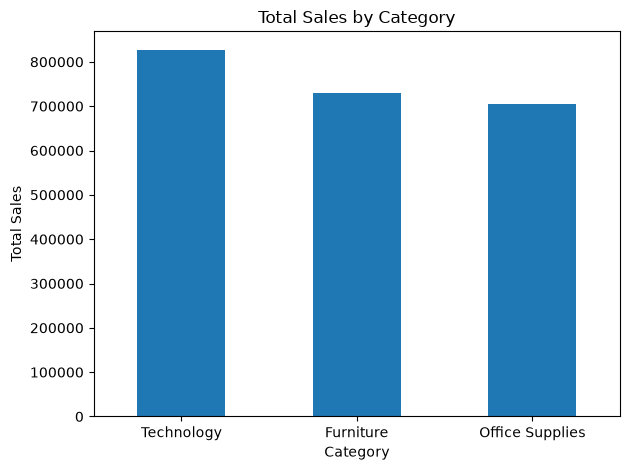

In [ ]:
category_sales.plot(kind="bar")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

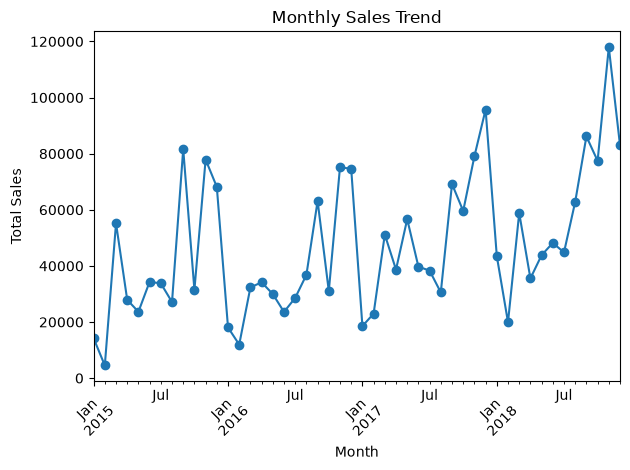

In [ ]:
monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
plt.savefig("category_sales.png", dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>

In [3]:
print(df["Segment"].unique())

<StringArray>
['Consumer', 'Corporate', 'Home Office']
Length: 3, dtype: str


In [4]:
segment_count = df["Segment"].value_counts()

print(segment_count)

Segment
Consumer       5101
Corporate      2953
Home Office    1746
Name: count, dtype: int64


In [5]:
segment_sales = df.groupby("Segment")["Sales"].sum()

print(segment_sales)

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64


In [6]:
segment_sales = segment_sales.sort_values(ascending=False)

print(segment_sales)

Segment
Consumer       1.148061e+06
Corporate      6.884941e+05
Home Office    4.249822e+05
Name: Sales, dtype: float64


In [7]:
total_sales = df["Sales"].sum()

segment_percentage = (segment_sales / total_sales) * 100

print(segment_percentage.round(2))

Segment
Consumer       50.76
Corporate      30.44
Home Office    18.79
Name: Sales, dtype: float64


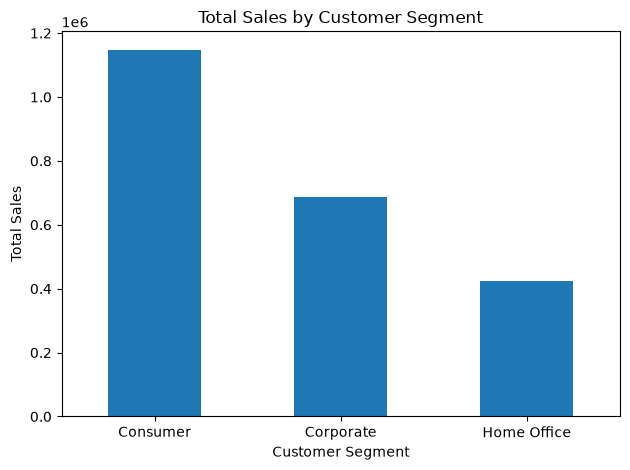

In [9]:
import matplotlib.pyplot as plt

segment_sales.plot(kind="bar")

plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig("segment_sales.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
segment_customers = df.groupby("Segment")["Customer ID"].nunique()

print(segment_customers)

Segment
Consumer       409
Corporate      236
Home Office    148
Name: Customer ID, dtype: int64


In [11]:
segment_summary = df.groupby("Segment").agg(
    Total_Sales=("Sales", "sum"),
    Unique_Customers=("Customer ID", "nunique"),
    Total_Orders=("Order ID", "nunique")
)

segment_summary["Sales_Percentage"] = (
    segment_summary["Total_Sales"] / df["Sales"].sum()
) * 100

segment_summary["Sales_Per_Customer"] = (
    segment_summary["Total_Sales"] / segment_summary["Unique_Customers"]
)

segment_summary = segment_summary.sort_values(
    by="Total_Sales",
    ascending=False
)

print(segment_summary.round(2))

             Total_Sales  Unique_Customers  Total_Orders  Sales_Percentage  \
Segment                                                                      
Consumer      1148060.53               409          2537             50.76   
Corporate      688494.07               236          1491             30.44   
Home Office    424982.18               148           894             18.79   

             Sales_Per_Customer  
Segment                          
Consumer                2806.99  
Corporate               2917.35  
Home Office             2871.50  


In [13]:
print(df["Sub-Category"].unique())

<StringArray>
[  'Bookcases',      'Chairs',      'Labels',      'Tables',     'Storage',
 'Furnishings',         'Art',      'Phones',     'Binders',  'Appliances',
       'Paper', 'Accessories',   'Envelopes',   'Fasteners',    'Supplies',
    'Machines',     'Copiers']
Length: 17, dtype: str


In [14]:
subcategory_count = df["Sub-Category"].value_counts()

print(subcategory_count)

Sub-Category
Binders        1492
Paper          1338
Furnishings     931
Phones          876
Storage         832
Art             785
Accessories     756
Chairs          607
Appliances      459
Labels          357
Tables          314
Envelopes       248
Bookcases       226
Fasteners       214
Supplies        184
Machines        115
Copiers          66
Name: count, dtype: int64


In [15]:
subcategory_sales = df.groupby("Sub-Category")["Sales"].sum()

print(subcategory_sales)

Sub-Category
Accessories    164186.7000
Appliances     104618.4030
Art             26705.4100
Binders        200028.7850
Bookcases      113813.1987
Chairs         322822.7310
Copiers        146248.0940
Envelopes       16128.0460
Fasteners        3001.9600
Furnishings     89212.0180
Labels          12347.7260
Machines       189238.6310
Paper           76828.3040
Phones         327782.4480
Storage        219343.3920
Supplies        46420.3080
Tables         202810.6280
Name: Sales, dtype: float64


In [16]:
subcategory_sales = subcategory_sales.sort_values(
    ascending=False
)

print(subcategory_sales)

Sub-Category
Phones         327782.4480
Chairs         322822.7310
Storage        219343.3920
Tables         202810.6280
Binders        200028.7850
Machines       189238.6310
Accessories    164186.7000
Copiers        146248.0940
Bookcases      113813.1987
Appliances     104618.4030
Furnishings     89212.0180
Paper           76828.3040
Supplies        46420.3080
Art             26705.4100
Envelopes       16128.0460
Labels          12347.7260
Fasteners        3001.9600
Name: Sales, dtype: float64


In [17]:
total_sales = df["Sales"].sum()

subcategory_percentage = (
    subcategory_sales / total_sales
) * 100

print(subcategory_percentage.round(2))

Sub-Category
Phones         14.49
Chairs         14.27
Storage         9.70
Tables          8.97
Binders         8.84
Machines        8.37
Accessories     7.26
Copiers         6.47
Bookcases       5.03
Appliances      4.63
Furnishings     3.94
Paper           3.40
Supplies        2.05
Art             1.18
Envelopes       0.71
Labels          0.55
Fasteners       0.13
Name: Sales, dtype: float64


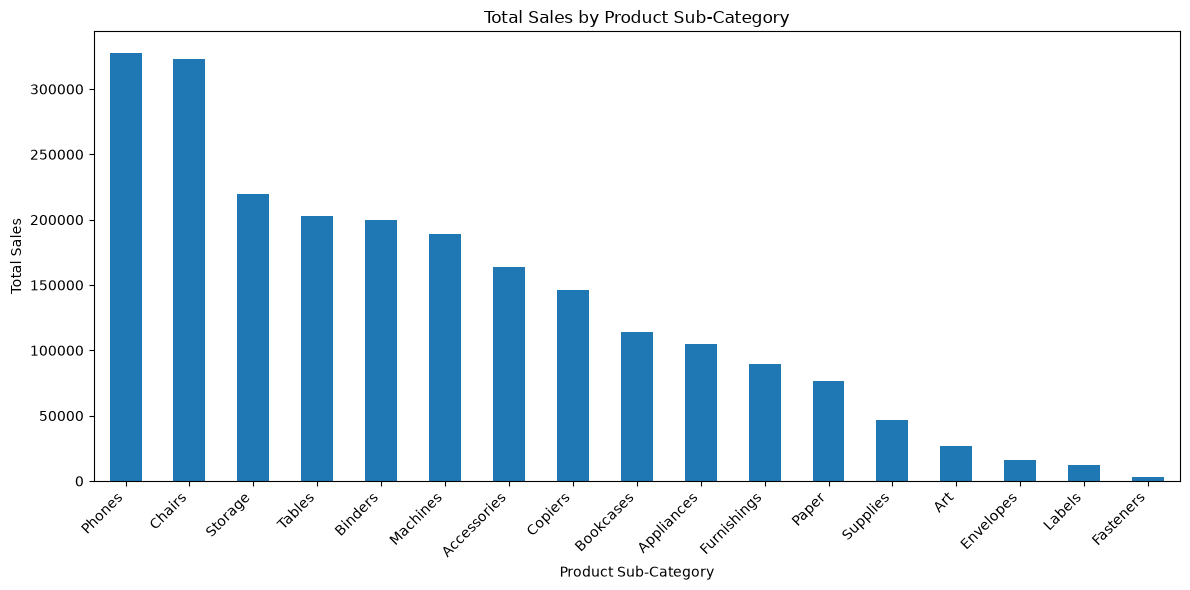

In [18]:
import matplotlib.pyplot as plt

subcategory_sales.plot(kind="bar", figsize=(12, 6))

plt.title("Total Sales by Product Sub-Category")
plt.xlabel("Product Sub-Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [19]:
print(df["Order Date"].dtype)

str


In [21]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d/%m/%Y"
)

print(df["Order Date"].dtype)

datetime64[us]


In [22]:
df["Year"] = df["Order Date"].dt.year

print(df[["Order Date", "Year"]].head())

  Order Date  Year
0 2017-11-08  2017
1 2017-11-08  2017
2 2017-06-12  2017
3 2016-10-11  2016
4 2016-10-11  2016


In [23]:
yearly_sales = df.groupby("Year")["Sales"].sum()

print(yearly_sales)

Year
2015    479856.2081
2016    459436.0054
2017    600192.5500
2018    722052.0192
Name: Sales, dtype: float64


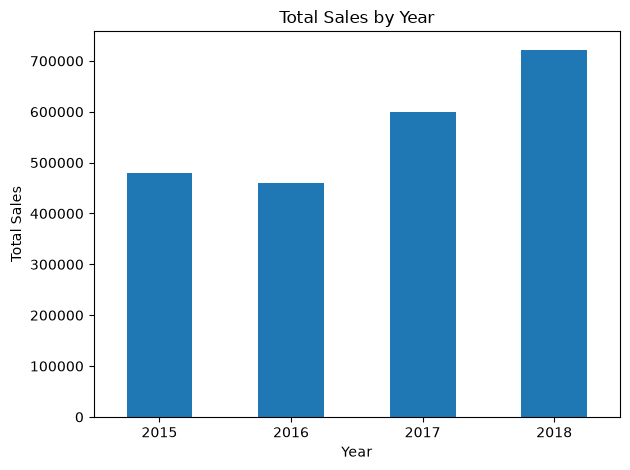

In [24]:
import matplotlib.pyplot as plt

yearly_sales.plot(kind="bar")

plt.title("Total Sales by Year")
plt.xlabel("Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [25]:
df["Month"] = df["Order Date"].dt.to_period("M")

print(df[["Order Date", "Month"]].head())

  Order Date    Month
0 2017-11-08  2017-11
1 2017-11-08  2017-11
2 2017-06-12  2017-06
3 2016-10-11  2016-10
4 2016-10-11  2016-10


In [26]:
monthly_sales = df.groupby("Month")["Sales"].sum()

print(monthly_sales)

Month
2015-01     14205.7070
2015-02      4519.8920
2015-03     55205.7970
2015-04     27906.8550
2015-05     23644.3030
2015-06     34322.9356
2015-07     33781.5430
2015-08     27117.5365
2015-09     81623.5268
2015-10     31453.3930
2015-11     77907.6607
2015-12     68167.0585
2016-01     18066.9576
2016-02     11951.4110
2016-03     32339.3184
2016-04     34154.4685
2016-05     29959.5305
2016-06     23599.3740
2016-07     28608.2590
2016-08     36818.3422
2016-09     63133.6060
2016-10     31011.7375
2016-11     75249.3995
2016-12     74543.6012
2017-01     18542.4910
2017-02     22978.8150
2017-03     51165.0590
2017-04     38679.7670
2017-05     56656.9080
2017-06     39724.4860
2017-07     38320.7830
2017-08     30542.2003
2017-09     69193.3909
2017-10     59583.0330
2017-11     79066.4958
2017-12     95739.1210
2018-01     43476.4740
2018-02     19920.9974
2018-03     58863.4128
2018-04     35541.9101
2018-05     43825.9822
2018-06     48190.7277
2018-07     44825.1040
2018-

In [27]:
best_month = monthly_sales.idxmax()
best_month_sales = monthly_sales.max()

worst_month = monthly_sales.idxmin()
worst_month_sales = monthly_sales.min()

print("Best month:", best_month)
print("Highest sales:", round(best_month_sales, 2))

print("Worst month:", worst_month)
print("Lowest sales:", round(worst_month_sales, 2))

Best month: 2018-11
Highest sales: 117938.16
Worst month: 2015-02
Lowest sales: 4519.89


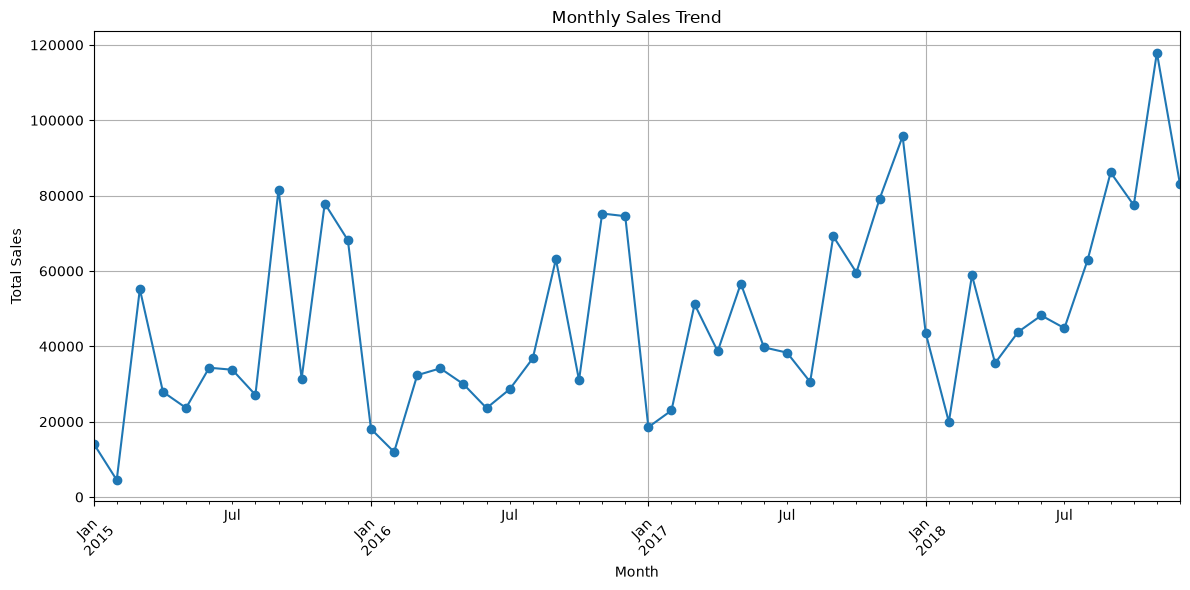

In [28]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="line", marker="o", figsize=(12, 6))

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
print("Best month:", best_month)
print("Highest sales:", round(best_month_sales, 2))
print("Worst month:", worst_month)
print("Lowest sales:", round(worst_month_sales, 2))

Best month: 2018-11
Highest sales: 117938.16
Worst month: 2015-02
Lowest sales: 4519.89


In [30]:
print(df[["Customer ID", "Customer Name", "Sales"]].head())

  Customer ID    Customer Name     Sales
0    CG-12520      Claire Gute  261.9600
1    CG-12520      Claire Gute  731.9400
2    DV-13045  Darrin Van Huff   14.6200
3    SO-20335   Sean O'Donnell  957.5775
4    SO-20335   Sean O'Donnell   22.3680


In [31]:
customer_sales = df.groupby(
    ["Customer ID", "Customer Name"]
)["Sales"].sum()

print(customer_sales.head())

Customer ID  Customer Name
AA-10315     Alex Avila       5563.560
AA-10375     Allen Armold     1056.390
AA-10480     Andrew Allen     1790.512
AA-10645     Anna Andreadi    5086.935
AB-10015     Aaron Bergman     886.156
Name: Sales, dtype: float64


In [32]:
top_10_customers = customer_sales.sort_values(
    ascending=False
).head(10)

print(top_10_customers)

Customer ID  Customer Name     
SM-20320     Sean Miller           25043.050
TC-20980     Tamara Chand          19052.218
RB-19360     Raymond Buch          15117.339
TA-21385     Tom Ashbrook          14595.620
AB-10105     Adrian Barton         14473.571
KL-16645     Ken Lonsdale          14175.229
SC-20095     Sanjit Chand          14142.334
HL-15040     Hunter Lopez          12873.298
SE-20110     Sanjit Engle          12209.438
CC-12370     Christopher Conant    12129.072
Name: Sales, dtype: float64


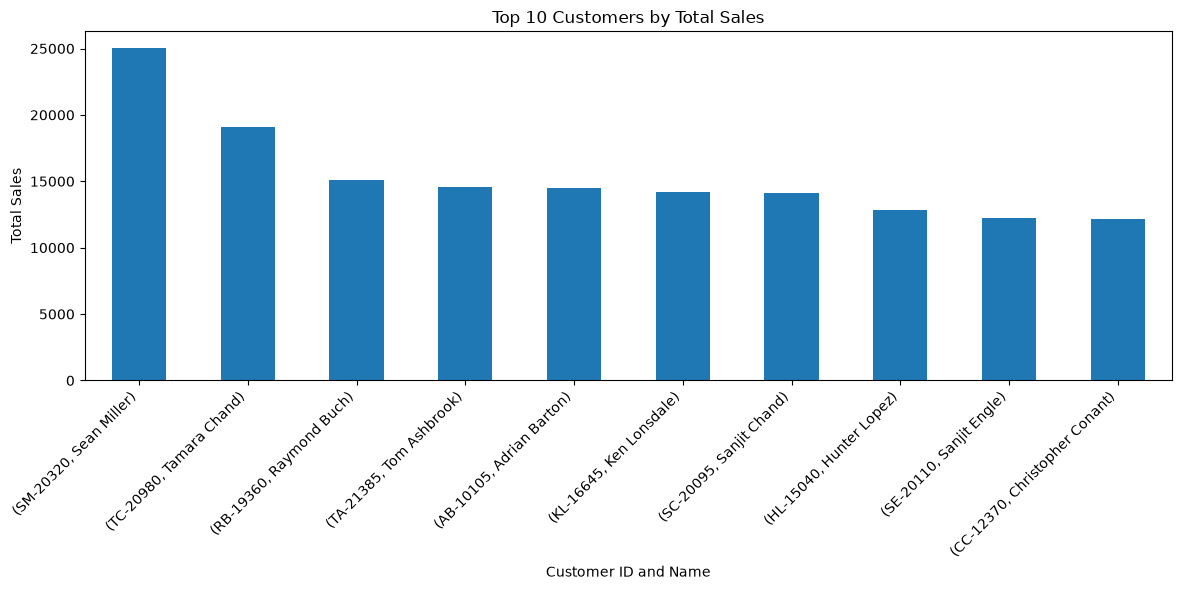

In [33]:
import matplotlib.pyplot as plt

top_10_customers.plot(kind="bar", figsize=(12, 6))

plt.title("Top 10 Customers by Total Sales")
plt.xlabel("Customer ID and Name")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [34]:
total_sales = df["Sales"].sum()

top_10_percentage = (
    top_10_customers / total_sales
) * 100

print(top_10_percentage.round(2))

Customer ID  Customer Name     
SM-20320     Sean Miller           1.11
TC-20980     Tamara Chand          0.84
RB-19360     Raymond Buch          0.67
TA-21385     Tom Ashbrook          0.65
AB-10105     Adrian Barton         0.64
KL-16645     Ken Lonsdale          0.63
SC-20095     Sanjit Chand          0.63
HL-15040     Hunter Lopez          0.57
SE-20110     Sanjit Engle          0.54
CC-12370     Christopher Conant    0.54
Name: Sales, dtype: float64


In [35]:
top_10_total = top_10_customers.sum()

top_10_share = (
    top_10_total / total_sales
) * 100

print("Top 10 customers' total sales:", round(top_10_total, 2))
print("Share of total sales:", round(top_10_share, 2), "%")

Top 10 customers' total sales: 153811.17
Share of total sales: 6.8 %


In [36]:
total_customers = df["Customer ID"].nunique()

average_sales_per_customer = total_sales / total_customers

print("Total unique customers:", total_customers)
print("Average sales per customer:", round(average_sales_per_customer, 2))

Total unique customers: 793
Average sales per customer: 2851.87


In [37]:
# 1. Best-performing customer segment
best_segment = segment_summary["Total_Sales"].idxmax()

# 2. Best-performing product sub-category
best_subcategory = subcategory_sales.idxmax()

# 3. Highest-sales year
best_year = yearly_sales.idxmax()

# 4. Top customer
best_customer = top_10_customers.index[0]

print("RETAIL SALES — KEY BUSINESS INSIGHTS")
print("------------------------------------")
print("Top customer segment:", best_segment)
print("Top product sub-category:", best_subcategory)
print("Highest-sales year:", best_year)
print("Top customer:", best_customer)

RETAIL SALES — KEY BUSINESS INSIGHTS
------------------------------------
Top customer segment: Consumer
Top product sub-category: Phones
Highest-sales year: 2018
Top customer: ('SM-20320', 'Sean Miller')


In [38]:
total_sales = df["Sales"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)

Total Sales: 2261536.78
Total Orders: 4922
Total Customers: 793


In [3]:
import sqlite3
import pandas as pd

# Create a copy so your original dataset stays unchanged
sql_df = df.copy()

# Convert the Month column to text if it contains monthly periods
if "Month" in sql_df.columns:
    sql_df["Month"] = sql_df["Month"].astype(str)

# Connect to your SQLite database
conn = sqlite3.connect(
    r"C:\Retail-Sales-Analytics\retail_sales.db"
)

# Import the dataset as a SQL table
sql_df.to_sql(
    "retail_sales",
    conn,
    if_exists="replace",
    index=False
)

print("Retail dataset imported successfully!")

Retail dataset imported successfully!


In [4]:
cursor = conn.cursor()

cursor.execute("SELECT COUNT(*) FROM retail_sales")

print("Total rows:", cursor.fetchone()[0])

Total rows: 9800


In [5]:
query = """
SELECT Category, SUM(Sales) AS Total_Sales
FROM retail_sales
GROUP BY Category
ORDER BY Total_Sales DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

          Category  Total_Sales
0       Technology  827455.8730
1        Furniture  728658.5757
2  Office Supplies  705422.3340


In [6]:
query = """
SELECT
    "Order ID",
    "Customer Name",
    Category,
    Sales
FROM retail_sales
WHERE Sales > 500
ORDER BY Sales DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

print(result)

         Order ID       Customer Name         Category      Sales
0  CA-2015-145317         Sean Miller       Technology  22638.480
1  CA-2017-118689        Tamara Chand       Technology  17499.950
2  CA-2018-140151        Raymond Buch       Technology  13999.960
3  CA-2018-127180        Tom Ashbrook       Technology  11199.968
4  CA-2018-166709        Hunter Lopez       Technology  10499.970
5  CA-2017-117121       Adrian Barton  Office Supplies   9892.740
6  CA-2015-116904        Sanjit Chand  Office Supplies   9449.950
7  US-2017-107440        Bill Shonely       Technology   9099.930
8  CA-2017-158841        Sanjit Engle       Technology   8749.950
9  CA-2017-143714  Christopher Conant       Technology   8399.976


In [7]:
query = """
SELECT
    COUNT(DISTINCT "Order ID") AS Total_Orders,
    COUNT(DISTINCT "Customer ID") AS Total_Customers
FROM retail_sales;
"""

result = pd.read_sql_query(query, conn)

print(result)

   Total_Orders  Total_Customers
0          4922              793


In [8]:
query = """
SELECT
    Region,
    SUM(Sales) AS Total_Sales
FROM retail_sales
GROUP BY Region
ORDER BY Total_Sales DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

    Region  Total_Sales
0     West  710219.6845
1     East  669518.7260
2  Central  492646.9132
3    South  389151.4590


In [9]:
query = """
SELECT
    Segment,
    SUM(Sales) AS Total_Sales,
    COUNT(DISTINCT "Customer ID") AS Unique_Customers
FROM retail_sales
GROUP BY Segment
ORDER BY Total_Sales DESC;
"""

result = pd.read_sql_query(query, conn)

print(result)

       Segment   Total_Sales  Unique_Customers
0     Consumer  1.148061e+06               409
1    Corporate  6.884941e+05               236
2  Home Office  4.249822e+05               148
